In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer



In [3]:
data= pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

In [4]:
print(f"Shape: {data.shape}")
display(data.head())
data.info()

Shape: (134967, 8)


,title,tag,artist,year,views,features,lyrics,id
0,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...,535805
1,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...,7519483
2,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...,4892808
3,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...,1584150
4,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...,7639050


<class 'pandas.DataFrame'>
RangeIndex: 134967 entries, 0 to 134966
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   title     134965 non-null  str  
 1   tag       134967 non-null  str  
 2   artist    134967 non-null  str  
 3   year      134967 non-null  int64
 4   views     134967 non-null  int64
 5   features  134967 non-null  str  
 6   lyrics    134967 non-null  str  
 7   id        134967 non-null  int64
dtypes: int64(3), str(5)
memory usage: 8.2 MB


In [5]:
data[data["title"].isna()]

,title,tag,artist,year,views,features,lyrics,id
12672,NaN,pop,Las Aves,2019,9,{},There's something more\nIn this life for me an...,7081034
118589,NaN,rock,Josh Gauton,2019,81,{},Let the waves crash over me\nMy sin [?] by lov...,4701034


In [6]:
dupe=data[data["lyrics"].duplicated()]
dupe.head()

,title,tag,artist,year,views,features,lyrics,id
13813,Always,pop,Plumb,2007,336,{},Out of nowhere\nYou came\nFrom a little dust\n...,1728585
20077,Paper Cup Words,pop,Elin Ruth,2015,62,{},I'll let it burn\nWords in a dirty paper cup\n...,2205183
21469,On The Sunny Side Of The Street Duet,pop,Tony Bennett,2011,289,"{""Willie Nelson""}","Grab your coat, grab your hat\nLeave your worr...",3651429
22585,Fascist Smash Punch Out mix,pop,Kill Switch...Klick,2015,57,{},Learn to hate for hatreds sake\nLearn to kill ...,1171570
26941,Honeysuckle Rose,pop,Fats Waller and His Rhythm,2015,130,{},Every honey bee fills with jealousy\nWhen they...,822768


In [7]:
target_lyrics = data.loc[13813, "lyrics"]
data[data["lyrics"] == target_lyrics]

,title,tag,artist,year,views,features,lyrics,id
3121,Always Bimbo Jones Extended Mix,pop,Plumb,2009,17,{},Out of nowhere\nYou came\nFrom a little dust\n...,1767177
13813,Always,pop,Plumb,2007,336,{},Out of nowhere\nYou came\nFrom a little dust\n...,1728585


In [8]:
data["tag"].value_counts()

tag
pop        55742
rap        38584
rock       25332
rb          6203
misc        5640
country     3466
Name: count, dtype: int64

In [9]:
data["word_count"]= data['lyrics'].fillna('').apply(lambda x: len(x.split()))
data

,title,tag,artist,year,views,features,lyrics,id,word_count
0,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...,535805,40
1,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...,7519483,425
2,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...,4892808,131
3,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...,1584150,271
4,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...,7639050,211
...,...,...,...,...,...,...,...,...,...
134962,Manhattan,pop,Tijuana Sweetheart,2007,48,{},If I knew when I was young that I'd be older\n...,1702980,302
134963,Belly Shit,rap,Lil Gotit,2019,3593,"{""Lil Troup""}",[Intro: Lil Gotit]\nCash\nWah-wah-wah\nWah-wah...,4802970,815
134964,The Four Loves,rock,Heath McNease,2014,301,{},[Verse 1]\nI was born inside a home\nThe young...,403929,214
134965,Ball And Chain,pop,Transmatic,2001,46,{},Rollin' by the pool the falling stars are not ...,1000723,246


In [10]:
data.drop(columns=['id']).describe()

,year,views,word_count
count,134967.000000,1.349670e+05,134967.000000
mean,2009.467537,3.413344e+03,317.614017
std,46.287743,4.192449e+04,451.526740
min,1.000000,0.000000e+00,1.000000
25%,2008.000000,2.200000e+01,158.000000
50%,2015.000000,8.900000e+01,244.000000
75%,2019.000000,4.730000e+02,377.000000
max,2024.000000,3.604497e+06,18221.000000


In [11]:
test['word_count'] = test['lyrics'].fillna('').str.split().str.len()
comparison = pd.DataFrame({
    'Train': [
        len(data),
        data['year'].median(),
        data['views'].median(),
        data['word_count'].median(),
        (data['features'].fillna('{}').str.strip() != '{}').mean() * 100
    ],
    'Test': [
        len(test),
        test['year'].median(),
        test['views'].median(),
        test['word_count'].median(),
        (test['features'].fillna('{}').str.strip() != '{}').mean() * 100
    ]
}, index=['Row Count', 'Median Year', 'Median Views', 'Median Word Count', 'Has Features (%)'])

display(comparison.round(2))

# Check Train/Test overlap (leakage indicators)
train_lyrics_set = set(data['lyrics'].dropna())
test_in_train_lyrics = test['lyrics'].isin(train_lyrics_set).mean()

train_artists_set = set(data['artist'].dropna())
test_in_train_artists = test['artist'].isin(train_artists_set).mean()

print(f"Test rows whose exact lyrics appear in Train: {test_in_train_lyrics:.2%}")
print(f"Test rows whose artist appears in Train:       {test_in_train_artists:.2%}")

,Train,Test
Row Count,134967.00,33742.00
Median Year,2015.00,2015.00
Median Views,89.00,88.00
Median Word Count,244.00,245.00
Has Features (%),17.07,17.38


Test rows whose exact lyrics appear in Train: 0.23%
Test rows whose artist appears in Train:       62.10%


In [12]:
old= data[data["year"] <1950]
print(old)



                                             title      tag  \
4                                        Get Ready  country   
513                        Dear Little Boy of Mine       rb   
542                           What Ought We To Do?     misc   
790                       Regular Man Blues Take 1      pop   
807                     The Battle of Life Chap. 2     misc   
...                                            ...      ...   
134531  Every Man out of His Humour Act 1. Scene 1     misc   
134585                              Aeneid: Book 3     misc   
134721                                Store Cypher      rap   
134725       Aeschylus’s “The Choephori Full Text”     misc   
134865                 The Faerie Queene  Book 6.2     misc   

                        artist  year  views  \
4          John Campbell Munro     1      2   
513           Carroll C. Clark  1921     22   
542       Gilbert and Sullivan  1879   1333   
790           Lottie Kimbrough  1924     15   
807     

year: 10,674 IQR outliers (bounds: [1991.5, 2035.5])
views: 20,834 IQR outliers (bounds: [-654.5, 1149.5])
word_count: 5,577 IQR outliers (bounds: [-170.5, 705.5])


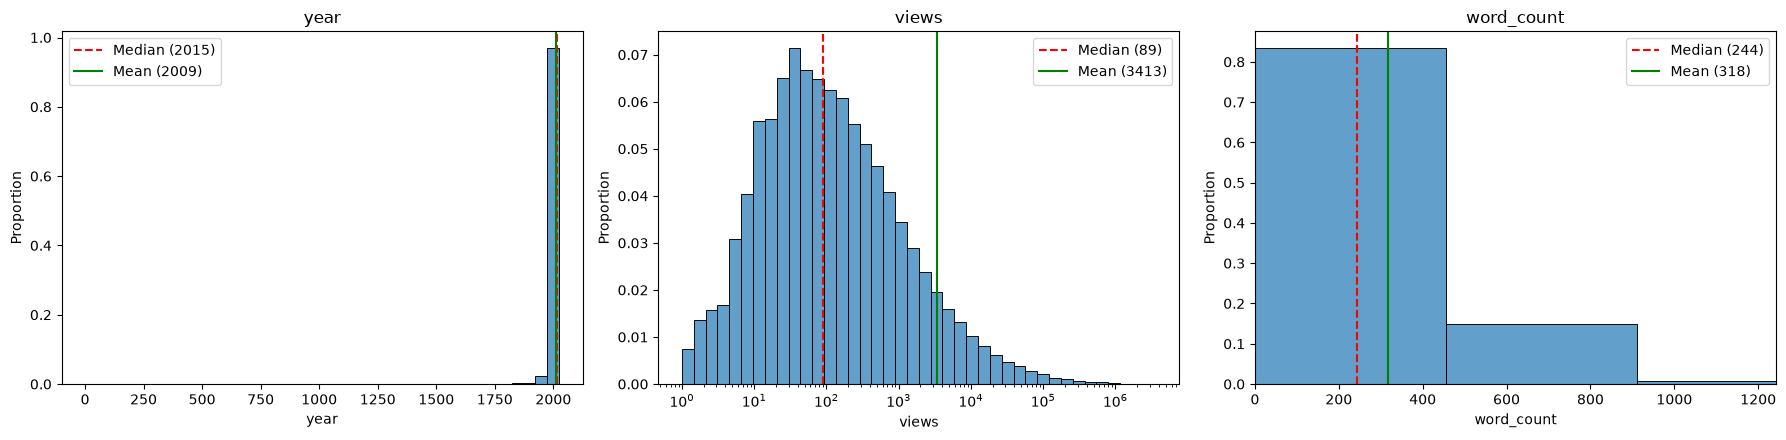

In [13]:
numeric_cols = [col for col in data.select_dtypes(include='number').columns if col != "id"]

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(6 * len(numeric_cols), 4.5))
if len(numeric_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, numeric_cols):
    median = data[col].median()
    mean = data[col].mean()

    # Calculate and print IQR outlier counts instead of cluttering the plot
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    l_bound, u_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((data[col] < l_bound) | (data[col] > u_bound)).sum()
    print(f"{col}: {n_outliers:,} IQR outliers (bounds: [{l_bound:.1f}, {u_bound:.1f}])")

    sns.histplot(
        data=data,
        x=col,
        bins=40,
        alpha=0.7,
        stat="proportion",
        log_scale=(col == "views"),
        ax=ax
    )

    ax.axvline(median, color='red', linestyle='--', linewidth=1.5, label=f'Median ({median:.0f})')
    ax.axvline(mean, color='green', linestyle='-', linewidth=1.5, label=f'Mean ({mean:.0f})')

    # Only clip extreme upper tail for word_count if present; keep full 'year' range to show anomalies
    if col == "word_count":
        ax.set_xlim(0, data[col].quantile(0.99))

    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()

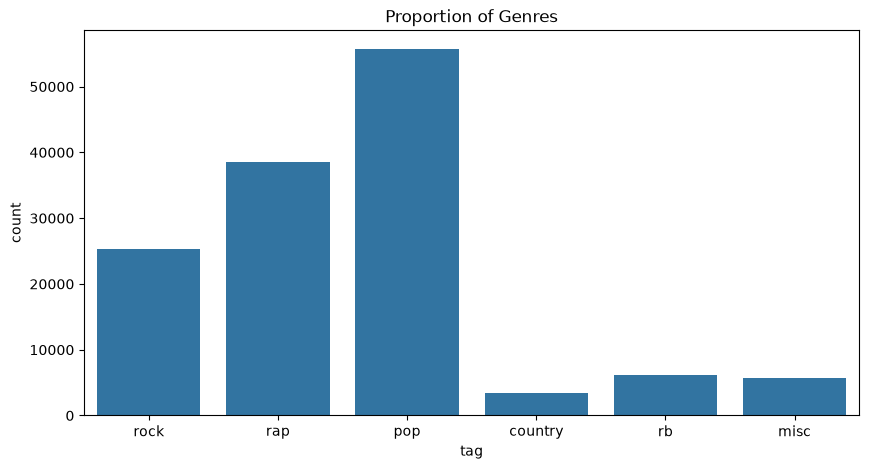

In [14]:
plt.figure(figsize=(10, 5))
sns.countplot(x='tag',data=data,)
plt.title("Proportion of Genres")
plt.show()

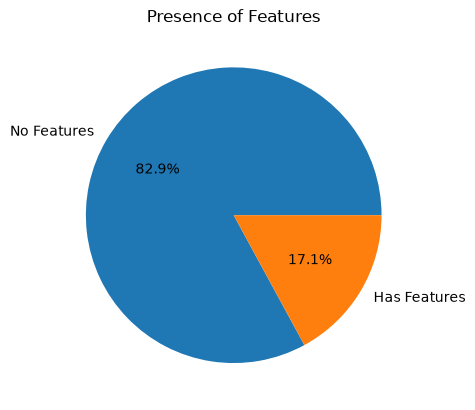

In [15]:
has_features = (data['features'] != '{}').map({True: 'Has Features', False: 'No Features'})
has_features.value_counts().plot.pie(autopct='%1.1f%%')
plt.title('Presence of Features')
plt.ylabel('')
plt.show()

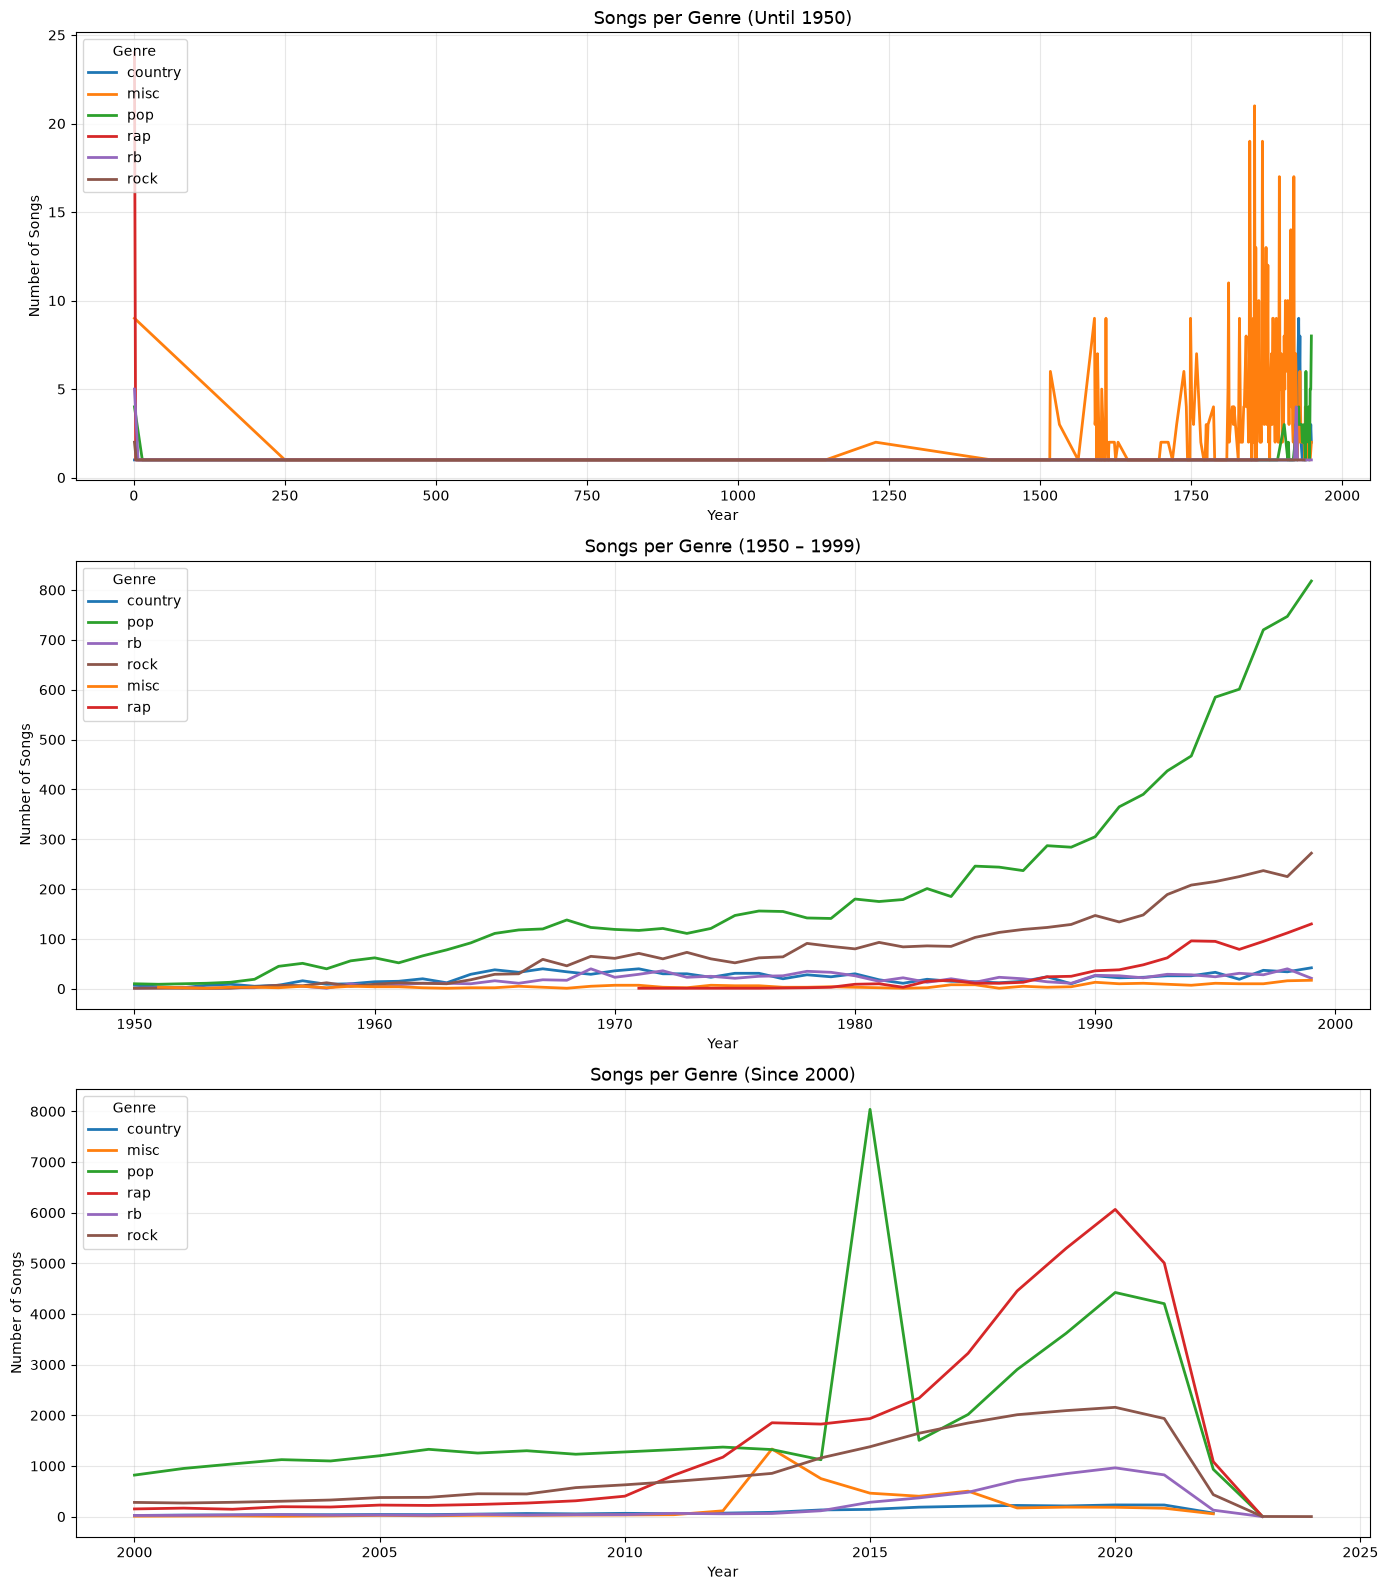

In [16]:
eras = [
    ("Until 1950", data[data['year'] < 1950]),
    ("1950 – 1999", data[(data['year'] >= 1950) & (data['year'] < 2000)]),
    ("Since 2000", data[(data['year'] >= 2000) & (data['year'] <= 2026)])
]

# Lock a consistent color for every genre across all three plots
genres = sorted(data['tag'].dropna().unique())
palette = dict(zip(genres, sns.color_palette("tab10", n_colors=len(genres))))

fig, axes = plt.subplots(3, 1, figsize=(14, 16))

for ax, (title, subset) in zip(axes, eras):
    genre_counts = subset.groupby(['year', 'tag']).size().reset_index(name='count')
    
    sns.lineplot(
        data=genre_counts,
        x='year',
        y='count',
        hue='tag',
        palette=palette,
        linewidth=2,
        ax=ax
    )
    
    ax.set_title(f"Songs per Genre ({title})", fontsize=13)
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of Songs")
    ax.legend(title="Genre", loc="upper left")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


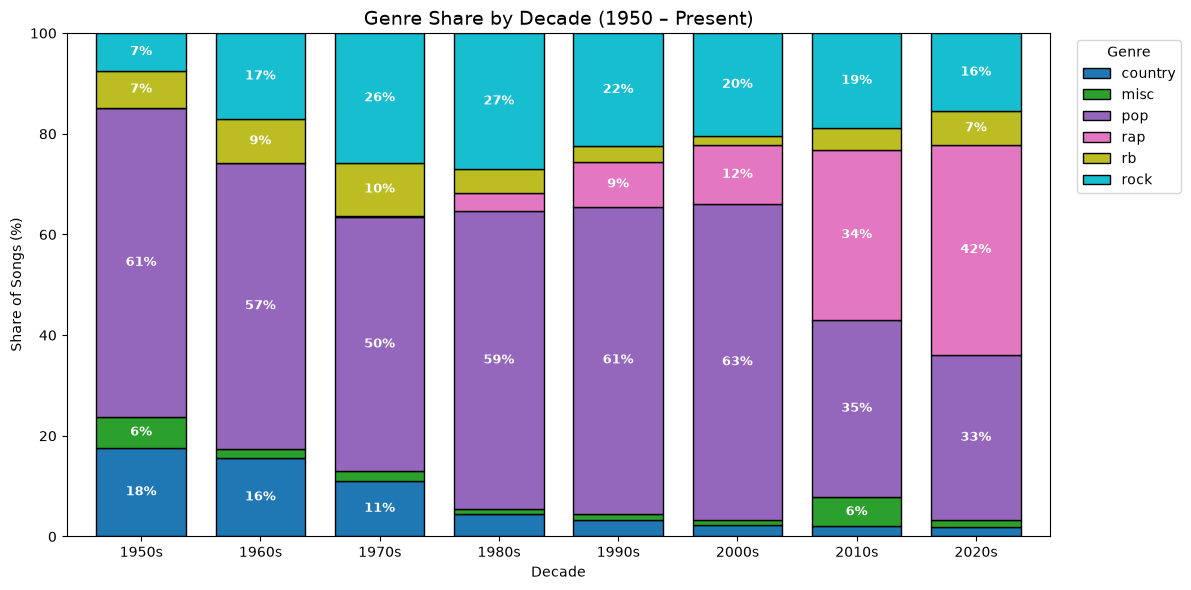

In [17]:
# Filter to valid years from 1950 onward and group into decades (1950s, 1960s, ..., 2020s)
df_decades = data[(data['year'] >= 1950) & (data['year'] <= 2026)].copy()
df_decades['decade'] = (df_decades['year'] // 10) * 10

# Compute percentage share of each genre per decade (rows sum to 100%)
decade_share = pd.crosstab(df_decades['decade'], df_decades['tag'], normalize='index') * 100

ax = decade_share.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='tab10',
    edgecolor='black',
    width=0.75
)

# Add percentage labels for segments large enough to read (>= 5%)
for container in ax.containers:
    labels = [f'{v:.0f}%' if v >= 5 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9, fontweight='bold', color='white')

plt.title('Genre Share by Decade (1950 – Present)', fontsize=14)
plt.xlabel('Decade')
plt.ylabel('Share of Songs (%)')
plt.ylim(0, 100)
plt.xticks(ticks=range(len(decade_share.index)), labels=[f"{d}s" for d in decade_share.index], rotation=0)
plt.legend(title='Genre', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_31752\425810550.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_artists, x='count', y='artist', palette='viridis')


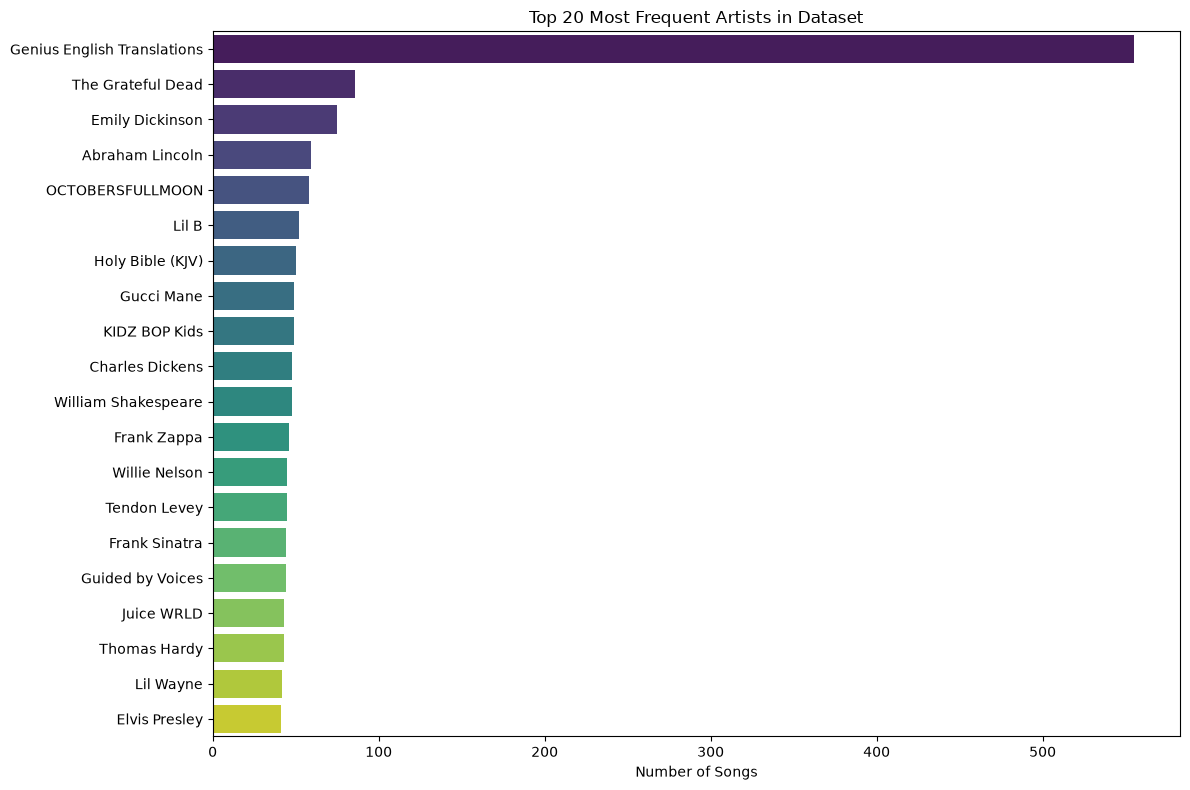

In [18]:
# Cell 2: Top 20 Most Frequent Artists Overall
plt.figure(figsize=(12, 8))

# Get the top 20 artists by row count
top_artists = data['artist'].value_counts().head(20).reset_index()
top_artists.columns = ['artist', 'count']

sns.barplot(data=top_artists, x='count', y='artist', palette='viridis')

plt.title('Top 20 Most Frequent Artists in Dataset')
plt.xlabel('Number of Songs')
plt.ylabel('')
plt.tight_layout()
plt.show()

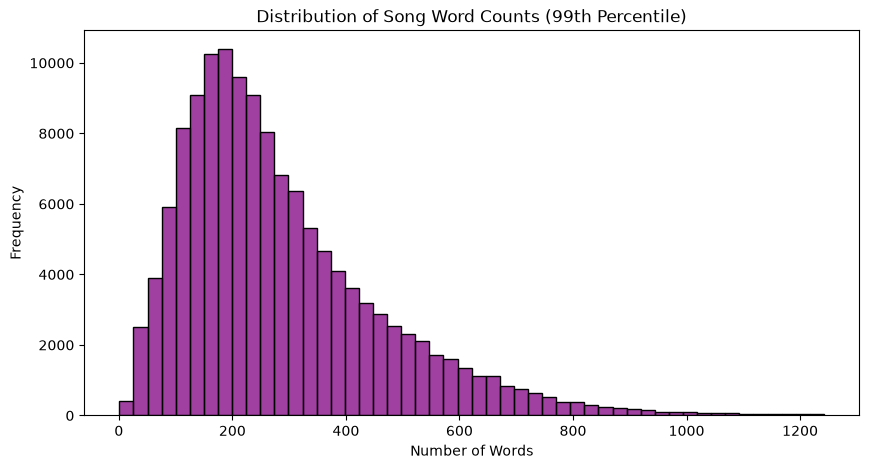

In [19]:
plt.figure(figsize=(10, 5))
upper_limit = data['word_count'].quantile(0.99)
sns.histplot(data=data[data['word_count'] <= upper_limit], x='word_count', bins=50, color='purple')

plt.title('Distribution of Song Word Counts (99th Percentile)')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

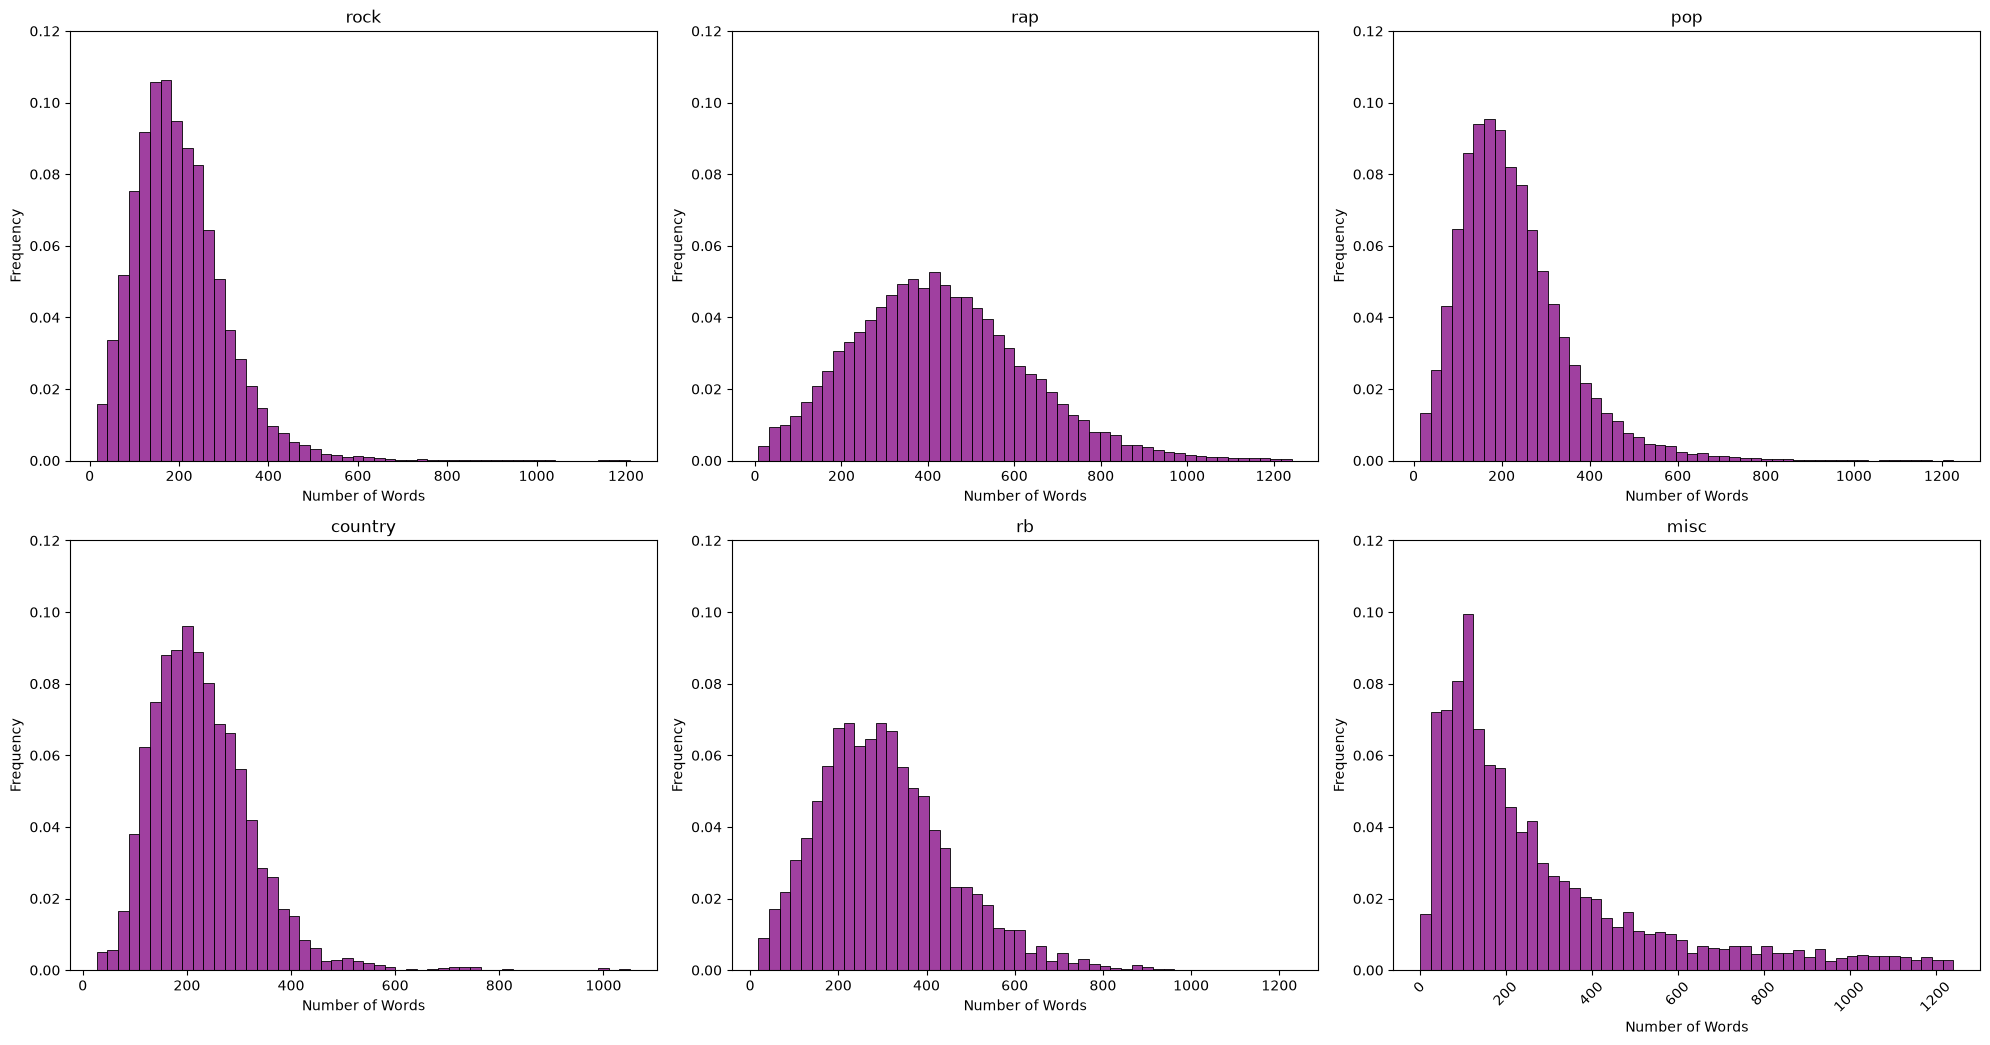

In [20]:
genre= data["tag"].unique()
plt.figure(figsize=(20, 15))
for i, col in enumerate(genre, 1):
    plt.subplot(len(genre)//3 + 1, 3, i,)
    genre_df = data[data['tag']== col]
    sns.histplot(data= genre_df[genre_df['word_count'] <= upper_limit], x="word_count", bins=50, color="purple", stat= "proportion")
    plt.ylim(0, 0.12)
    plt.title(col)
    plt.xlabel("Number of Words")
    plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

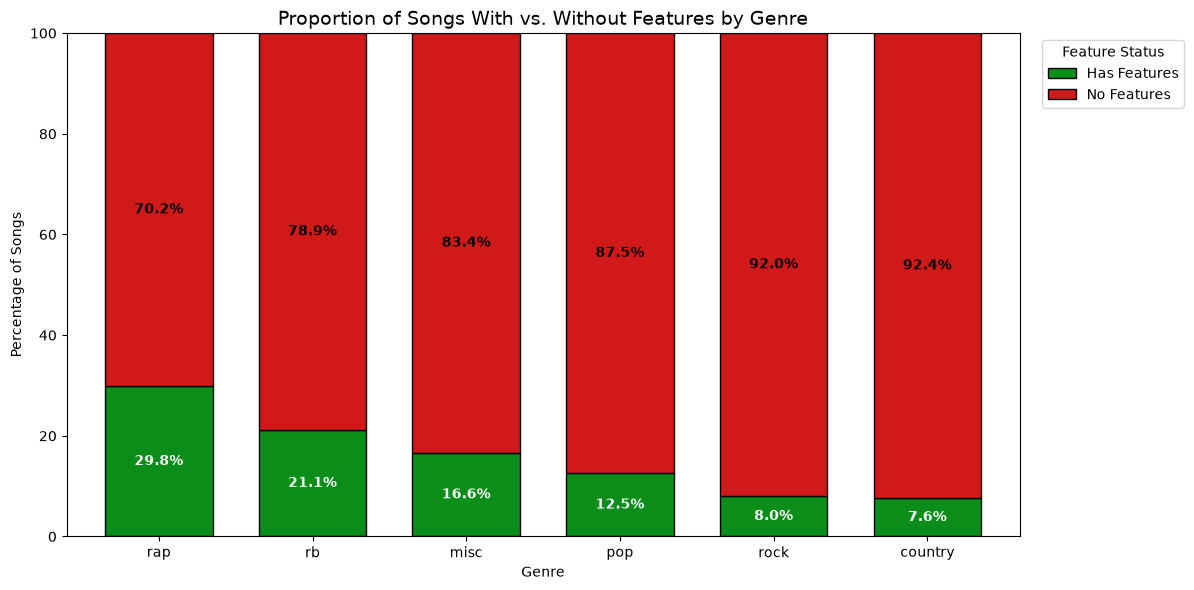

In [21]:
data['has_features'] = data['features'].fillna('{}').apply(
    lambda x: 'Has Features' if x.strip() != '{}' else 'No Features'
)

# 2. Compute percentage breakdown within each genre (rows sum to 100%)
genre_feat_pct = pd.crosstab(data['tag'], data['has_features'], normalize='index') * 100

# Sort genres by highest percentage of songs WITH features
genre_feat_pct = genre_feat_pct[['Has Features', 'No Features']].sort_values(
    by='Has Features', ascending=False
)

# 3. Plot 100% stacked bar chart
ax = genre_feat_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=["#0a8d19", "#d01919"],
    edgecolor='black',
    width=0.7
)

# 4. Add percentage labels inside each bar segment
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        label_type='center',
        fontsize=10,
        fontweight='bold',
        color='white' if container == ax.containers[0] else 'black'
    )

plt.title('Proportion of Songs With vs. Without Features by Genre', fontsize=14)
plt.xlabel('Genre')
plt.ylabel("Percentage of Songs")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Feature Status', loc='upper right', bbox_to_anchor=(1.18, 1))
plt.tight_layout()
plt.show()

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_31752\485902769.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_by_genre, x='tag', y='share_with_features', palette='viridis', ax=axes[1])


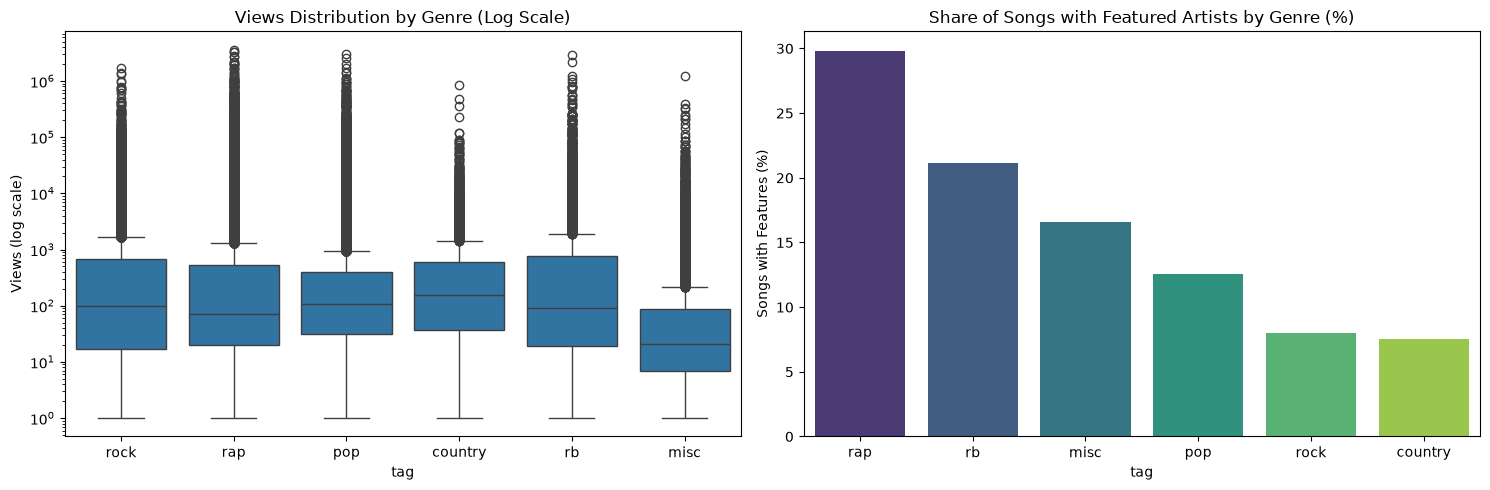

,tag,share_with_features,mean_n_features
0,rap,29.83,0.42
1,rb,21.13,0.26
2,misc,16.60,0.23
3,pop,12.54,0.16
4,rock,8.01,0.11
5,country,7.56,0.11


In [22]:
def count_features(val):
    val = str(val).strip()
    if val in ('', '{}', 'nan', 'None'):
        return 0
    return val.count(',') + 1

data['n_features'] = data['features'].apply(count_features)
data['has_features'] = data['n_features'] > 0

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Views by genre (boxplot on log scale)
sns.boxplot(data=data[data['views'] > 0], x='tag', y='views', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Views Distribution by Genre (Log Scale)')
axes[0].set_ylabel('Views (log scale)')

# 2. Share of songs with features per genre + mean n_features
feat_by_genre = data.groupby('tag').agg(
    share_with_features=('has_features', lambda s: s.mean() * 100),
    mean_n_features=('n_features', 'mean')
).sort_values('share_with_features', ascending=False).reset_index()

sns.barplot(data=feat_by_genre, x='tag', y='share_with_features', palette='viridis', ax=axes[1])
axes[1].set_title('Share of Songs with Featured Artists by Genre (%)')
axes[1].set_ylabel('Songs with Features (%)')

plt.tight_layout()
plt.show()
display(feat_by_genre.round(2))

Very short lyrics (< 10 words): 4


,title,artist,tag,word_count,lyrics
14149,Activated part 1 - Origins of a Rap Acrobat,Rebel XD,rap,8,This page has been moved to here... http://gen...
60627,Heart,Mary howe,misc,9,Death to your heart ...
109406,South Africa Album Releases November 2022,Genius South Africa,misc,4,Date To Be Announced01.1102.1103.1104.1105.110...
124488,Alison Ritz Margaret Weisman’s “Minimum Wage ...,NYRitz,misc,1,http://www.theatlantic.com/business/archive/20...


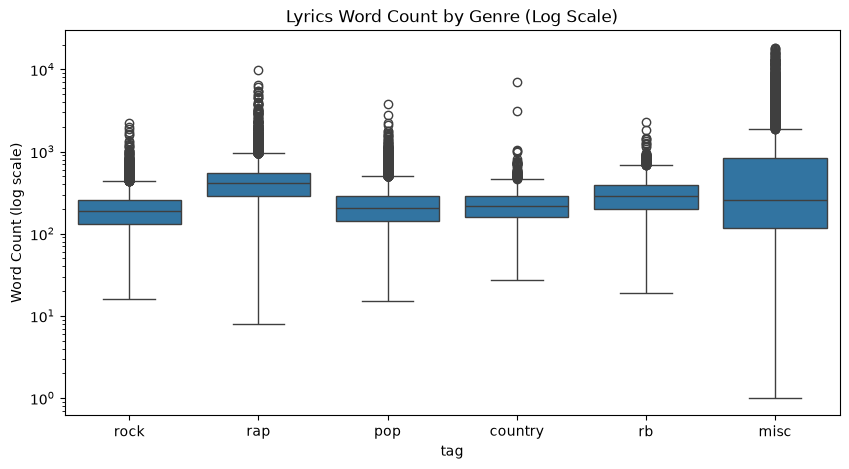

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_31752\3046432949.py:18: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  data['has_section_tags'] = data['lyrics'].fillna('').str.contains(section_pattern, regex=True)


Share of songs with section tags: 46.2%

Top 10 Section Tags:
lyrics
Verse          111791
Chorus          78329
?               20562
Pre-Chorus      15568
Hook            14788
Bridge          14474
Outro           13684
Intro           11328
Post-Chorus      3773
                 3373
Name: count, dtype: int64

Songs with '[?]' placeholder: 5650
Songs with non-ASCII characters: 42.4%

Top 10 Distinctive Words per Genre:
  country   : love, chorus, verse, just, don, know, like, got, time, way
  misc      : said, like, man, shall, know, love, time, did, day, don
  pop       : love, don, know, just, chorus, like, time, let, want, baby
  rap       : like, got, yeah, don, ain, shit, bitch, know, just, nigga
  rb        : love, baby, yeah, know, don, just, chorus, like, girl, wanna
  rock      : chorus, don, know, just, verse, time, love, like, away, life


In [23]:

# 1. Word & character lengths + empty/short check
data['char_count'] = data['lyrics'].fillna('').str.len()
data['word_count'] = data['lyrics'].fillna('').str.split().str.len()

print("Very short lyrics (< 10 words):", (data['word_count'] < 10).sum())
display(data[data['word_count'] < 10][['title', 'artist', 'tag', 'word_count', 'lyrics']].head(10))

# Boxplot of word_count by genre on a log scale
plt.figure(figsize=(10, 5))
sns.boxplot(data=data[data['word_count'] > 0], x='tag', y='word_count')
plt.yscale('log')
plt.title('Lyrics Word Count by Genre (Log Scale)')
plt.ylabel('Word Count (log scale)')
plt.show()

# 2. Section tags ([Chorus], [Verse 1], etc.)
section_pattern = r'\[([^\]]+)\]'
data['has_section_tags'] = data['lyrics'].fillna('').str.contains(section_pattern, regex=True)
print(f"Share of songs with section tags: {data['has_section_tags'].mean():.1%}")

# Most common section tags (normalize numbers like [Verse 1] -> Verse)
all_tags = data['lyrics'].fillna('').str.findall(section_pattern).explode().dropna()
clean_tags = all_tags.str.replace(r'\s*\d+.*', '', regex=True).str.strip()
print("\nTop 10 Section Tags:")
print(clean_tags.value_counts().head(10))

# 3. Noise check: [?] placeholders & non-ASCII characters (non-English / zero-width chars)
print("\nSongs with '[?]' placeholder:", data['lyrics'].fillna('').str.contains(r'\[\?\]', regex=True).sum())
has_non_ascii = data['lyrics'].fillna('').apply(lambda s: not s.isascii())
print(f"Songs with non-ASCII characters: {has_non_ascii.mean():.1%}")

# 4. Most distinctive words per genre using TF-IDF
tfidf = TfidfVectorizer(stop_words='english', max_features=5000, token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
X_tfidf = tfidf.fit_transform(data['lyrics'].fillna(''))
terms = np.array(tfidf.get_feature_names_out())

print("\nTop 10 Distinctive Words per Genre:")
for genre in sorted(data['tag'].unique()):
    mask = (data['tag'] == genre).values
    mean_tfidf = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
    top_words = terms[mean_tfidf.argsort()[::-1][:10]]
    print(f"  {genre:<10}: {', '.join(top_words)}")

In [27]:
print(data.iloc[124488]['lyrics'])

http://www.theatlantic.com/business/archive/2013/12/should-we-raise-the-minimum-wage-11-questions-and-answers/282326/


In [31]:
url_pattern = r'(?:https?://|www\.)\S+'
train_urls = data[data['lyrics'].fillna('').str.contains(url_pattern, case=False, regex=True)]
print(f"Total rows in test with URLs in lyrics: {len(train_urls)}")
if len(train_urls) > 0:
    print(train_urls[['title', 'artist', 'year', 'lyrics']].tail(15))
    # Also check how many are ONLY a URL vs containing a URL inside text
    only_url = test['lyrics'].fillna('').str.strip().str.match(r'^(?:https?://|www\.)\S+$', case=False)
    print(f"Rows in train where lyrics is ONLY a URL: {only_url.sum()}")

Total rows in test with URLs in lyrics: 169
                                                    title  \
124488  Alison Ritz  Margaret Weisman’s “Minimum Wage ...   
124576                                          Dark Lady   
124990                               F.T.W. FCK The World   
127345                                      Ellen Hollman   
128044                              The New Word: Part 10   
128499           AMP Electrical Distribution  Wholesalers   
130383                                      International   
130433                    Feel the happiness in your Life   
130835                                The SituFuckiwation   
130858                      Cane: A Critical Introduction   
131410                        The end of a miserable life   
131907                 When I Grow up Interlude by Sammie   
132543                                    Broken and Torn   
132844  GMOs are agricultural warfare biotech expert a...   
133995  Angus Steak and Egg Sandwich and 

In [29]:
print(data.iloc[2761]['lyrics'])

[Verse 1]
So I won’t disturb you
You’re looking perfect
In the suburbia sun
Yeah I met your neighbor
She knows I’m a faker
She knows I’ll never belong
Behind little white fences
Porches and pensions

No I won’t disturb you
You keep being perfect
You’ll make somebody happy
I’m Not Ready To

[Chorus]
Settle down
To a little town life
Living perfectly polite
I’m too immature
Settle down
Get it out of your mind
I’m not calling you mine
So don’t call me yours
Cause I know I’m gonna let you down
You down
You down
I’m not ready, ready for the Suburbs
I’m not ready
So settle down
[Verse 2]
Boy you’re so damn pretty
You’re not for the city
We’ll end up spitting you out
It’s a cutthroat fire pit
I guess that’s why I like it
None of us ever keep count
Of our minor offenses
The who slept in whose beds

Boy you’re so damn pretty
You’re not for the city
I don’t think that you should come around

[Chorus]
Settle down
To a little town life
Living perfectly polite
I’m too immature
Settle down
Get it ou

In [32]:
url_pattern = r'(?:https?://|www\.)\S+'
only_single_url_pattern = r'^(?:https?://|www\.)\S+$'

for name, df in [('train (data)', data), ('test', test)]:
    lyrics_clean = df['lyrics'].fillna('').str.strip()
    
    # 1. Contains at least one URL anywhere
    has_url = lyrics_clean.str.contains(url_pattern, case=False, regex=True)
    
    # 2. Entire lyrics is a single URL (like row 124488)
    only_one_url = lyrics_clean.str.match(only_single_url_pattern, case=False)
    
    # 3. Entire lyrics consists ONLY of URLs (e.g., multiple links separated by \n, no words)
    no_text_outside_urls = lyrics_clean.str.replace(url_pattern, '', case=False, regex=True).str.strip() == ''
    only_urls = has_url & no_text_outside_urls
    
    print(f"=== {name} ===")
    print(f"  Rows containing any URL:           {has_url.sum()}")
    print(f"  Rows with ONLY a single URL:       {only_one_url.sum()}")
    print(f"  Rows with ONLY URLs (1 or more):   {only_urls.sum()}\n")

# Inspect the train rows where lyrics is ONLY URL(s)
train_only_urls = data[
    data['lyrics'].fillna('').str.contains(url_pattern, case=False, regex=True) &
    (data['lyrics'].fillna('').str.replace(url_pattern, '', case=False, regex=True).str.strip() == '')
]
display(train_only_urls[['title', 'artist', 'tag', 'year', 'lyrics']].head(15))

=== train (data) ===
  Rows containing any URL:           169
  Rows with ONLY a single URL:       1
  Rows with ONLY URLs (1 or more):   1

=== test ===
  Rows containing any URL:           38
  Rows with ONLY a single URL:       0
  Rows with ONLY URLs (1 or more):   0



,title,artist,tag,year,lyrics
124488,Alison Ritz Margaret Weisman’s “Minimum Wage ...,NYRitz,misc,2014,http://www.theatlantic.com/business/archive/20...


In [38]:

url_pattern = r'(?:https?://|www\.)\S+'

url_counts = data['lyrics'].fillna('').str.count(url_pattern, flags=2) # re.IGNORECASE = 2
multi_url = data[url_counts > 2]
print(f"Test rows with > 1 URL: {len(multi_url)}")
if len(multi_url) > 2:
    print(multi_url[['title', 'artist', 'year', 'lyrics']].head(5))

Test rows with > 1 URL: 18
                                                   title  \
17561  Institutionalized Organizations: Formal Struct...   
39369                                Keranique hair care   
41896                       Vitrification Of Blood Pt. 1   
42484                                              Intro   
48105                                     The First Step   

                             artist  year  \
17561  Meyer, John and Rowan, Brian  2017   
39369                   Varni james  2016   
41896             Blood Incantation  2016   
42484              Capone-N-Noreaga  2015   
48105               Wandering Monks  2011   

                                                  lyrics  
17561  Institutionalized Organizations: Formal Struct...  
39369  Keranique hair care can make your hair with al...  
41896  Falling...\nFall through the...\nStargate\nWit...  
42484  (Carl Thomas)\nI was born by the river.. in a ...  
48105  CHORUS\n\n[MCAD]\nSome people get scare

In [43]:
print(data.iloc[17561]['lyrics'])

Institutionalized Organizations: Formal Structure as Myth and Ceremony
Author(s): John W. Meyer and Brian Rowan
Source: American Journal of Sociology, Vol. 83, No. 2 (Sep., 1977), pp. 340-363
Published by: The University of Chicago Press
Stable URL: http://www.jstor.org/stable/2778293
Accessed: 12-01-2017 19:22 UTC
REFERENCES Linked references are available on JSTOR for this article:http://www.jstor.org/stable/2778293?seq=1&cid=pdf-reference#references_tab_contents You may need to log in to JSTOR to access the linked references.
JSTOR is a not-for-profit service that helps scholars, researchers, and students discover, use, and build upon a wide range of content in a trusteddigital archive. We use information technology and tools to increase productivity and facilitate new forms of scholarship. For more information aboutJSTOR, please contact support@jstor.org. Your use of the JSTOR archive indicates your acceptance of the Terms & Conditions of Use, available athttp://about.jstor.org/ter

In [ ]:
url_pattern = r'(?:https?://|www\.)\S+'

# Count URLs per row in train ('data')
url_counts = data['lyrics'].fillna('').str.count(url_pattern, flags=re.IGNORECASE)

# 1. Songs with AT LEAST ONE URL (>= 1)
has_url = data[url_counts >= 1]
misc_any = (has_url['tag'] == 'misc').sum()
print(f"Train rows with >= 1 URL: {len(has_url)}")
print(f"  -> Of these, 'misc' count: {misc_any} ({misc_any / len(has_url):.1%})\n")

print("Genre breakdown for rows with >= 1 URL:")
breakdown_any = pd.DataFrame({
    'count': has_url['tag'].value_counts(),
    'pct (%)': (has_url['tag'].value_counts(normalize=True) * 100).round(2)
})
display(breakdown_any)

# 2. Songs with MORE THAN ONE URL (> 1)
multi_url = data[url_counts > 1]
misc_multi = (multi_url['tag'] == 'misc').sum()
print(f"\nTrain rows with > 1 URL: {len(multi_url)}")
print(f"  -> Of these, 'misc' count: {misc_multi} ({misc_multi / len(multi_url):.1%})")

Train rows with >= 1 URL: 169
  -> Of these, 'misc' count: 81 (47.9%)

Genre breakdown for rows with >= 1 URL:


,count,pct (%)
tag,,
misc,81,47.93
rap,43,25.44
pop,26,15.38
rock,11,6.51
country,5,2.96
rb,3,1.78



Train rows with > 1 URL: 41
  -> Of these, 'misc' count: 27 (65.9%)


: 